# Conditional Graph

### Import Module

In [17]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph, START, END

In [ ]:
class AgentState(TypedDict):
    number1: int
    number2: int
    operator1: str
    result: int

In [19]:
def add_node(state: AgentState) -> AgentState:
    state["result"] = state["number1"] + state["number2"]
    return state


def sub_node(state: AgentState) -> AgentState:
    state["result"] = state["number1"] - state["number2"]
    return state


def decision_node(state: AgentState) -> AgentState:
    if state["operator"] == "+":
        return "addition_node"
    elif state["operator"] == "-":
        return "subraction_node"

In [23]:
graph = StateGraph(AgentState)

graph.add_node("add_node", add_node)
graph.add_node("sub_node", sub_node)
graph.add_node("router", lambda state:state)

graph.add_edge(START, "router")
graph.add_conditional_edges(
    "router",
    decision_node,
    {
        "addition_node": "add_node",
        "subraction_node": "sub_node"
    }
)
graph.add_edge("add_node", END)
graph.add_edge("sub_node", END)

app = graph.compile()

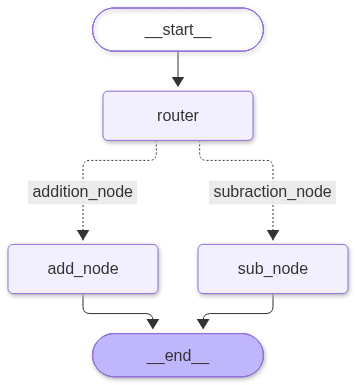

In [25]:
from IPython.display import display, Image

display(Image(app.get_graph().draw_mermaid_png()))

In [27]:
result = app.invoke({
    "number1": 5,
    "number2": 7,
    "operator": "-"
})

result["result"]

-2